# Pretrained visual SAE: real features, overlays and evaluation

We load DINO ViT-B/16 and a published Prisma ReLU dictionary, without training
either model. The dictionary observes block 11's residual output **before**
DINO's final normalization. We analyze the 196 image patches, excluding CLS.

Thirty-two fixed COCO **train2017** photographs select feature IDs and a
reconstruction reference mean. The three **val2017** person/car/dog images
are the report's fixed examples; their IDs and hashes are excluded from
calibration. No held-out feature selection or fitting takes place.
A feature ID is a dictionary coordinate, not a semantic concept label.

Install this checkout with `pip install -e '.[transformers,sae,visualization]'`.
Historical Prisma envelopes require PyTorch >=2.6 (restricted weights-only loader).
An 8 GB CUDA GPU is recommended; CPU works more slowly. Downloads are about
343 MB for the backbone, 302 MB for the SAE, and several MB of calibration
photographs. Raw files may be cached; every activation and score is computed
by the cells below. Model weights and photograph rights remain with their
respective authors; see the linked model cards and image source notices.


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

New Colab checkouts use the reviewed source **gexinh/vlm-probe** at commit
`e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1`. This pins the runtime source for
reproducible execution.

Optional environment settings: VLM_PROBING_REPOSITORY and VLM_PROBING_REF
override that pinned repository and commit; VLM_PROBING_COLAB_DIR changes
the checkout directory (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [1]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "gexinh/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get(
        "VLM_PROBING_REF", "e2613bf7ef55f1889aa9f95d2004d1ab6770c1b1"
    )
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


Local runtime: using the existing checkout and environment.


In [2]:
%matplotlib inline
import hashlib
import json
import os
import time
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from huggingface_hub import hf_hub_download
from transformers import ViTModel

from vlmprobe import Prober, evaluation
from vlmprobe.adapters.prisma_vision import make_adapter
from vlmprobe.sae.binding import build_sae_binding
from vlmprobe.sae.importers import import_checkpoint
from vlmprobe.visualization import plot_sae_evaluation, plot_sae_feature_overlay

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/sae_report_samples.json").is_file())
OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", str(ROOT / "outputs/sae_pretrained")))
OUT.mkdir(parents=True, exist_ok=True)
CACHE = Path(os.environ.get("VLM_PROBING_DATA_CACHE", str(Path.home() / ".cache/vlmprobe/sae_pretrained")))
COCO_DIR = Path(os.environ.get("VLM_PROBING_COCO_DIR", str(CACHE / "coco2017")))
DEVICE = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
MODEL_ID = "facebook/dino-vitb16"
MODEL_REVISION = "f205d5d8e640a89a2b8ef0369670dfc37cc07fc2"
SAE_ID = "Prisma-Multimodal/DINO-vanilla-x64-all_patches_11-resid_post-1085-99"
SAE_REVISION = "3e3ea0cdcde4186db8069f4fe0ce219e8693155a"
MODEL_FILES = {
    "config.json": "b87c0270b97db085fd82cf114a761fd0f62ae7914fbd407c752a2260646b689c",
    "pytorch_model.bin": "a064e36c67289caaa5c949c0b3f7f31a0fcbcba5721f5fa12419933ec1f4fe6e",
}
SAE_FILES = {
    "config.json": "5a647f1f0c23b2c4763bbfd2a729ee605d2b36b19ba42d67fa238af41ee0702d",
    "weights.pt": "ba04901a22b0a8b37255246fec6eb8cdb8e0592e844754527ab6d9e7f679f8fd",
}
torch.manual_seed(17)
torch.set_num_threads(int(os.environ.get("VLM_PROBING_CPU_THREADS", "4")))
if DEVICE.startswith("cuda"):
    # Keep this source-parity walkthrough in float32, including GEMMs.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False


def checksum(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def status(state, **fields):
    payload = {"status": state, "updated_unix": time.time(), **fields}
    temporary = OUT / "status.tmp.json"
    temporary.write_text(json.dumps(payload, indent=2) + "\n")
    temporary.replace(OUT / "status.json")
    print(json.dumps(payload), flush=True)


def pinned_files(repo, revision, expected, destination):
    destination.mkdir(parents=True, exist_ok=True)
    for name, digest in expected.items():
        path = destination / name
        if not path.is_file():
            hf_hub_download(repo, name, revision=revision, local_dir=destination)
        if checksum(path) != digest:
            raise ValueError(f"checksum mismatch for {repo}/{name}; do not use this file")
    return destination


## Raw photographs and annotations

The versioned input manifest contains original COCO image IDs, source URLs,
SHA-256 checksums and noncrowd bounding boxes. It contains **no model outputs**.
The three original report photographs are bundled; calibration photographs
are downloaded from their original source if absent. The calibration subset
was selected by annotation and image ID, before any feature computation.


In [3]:
manifest_path = ROOT / "demos/assets/sae_report_samples.json"
manifest = json.loads(manifest_path.read_text())
calibration_records = manifest["calibration"]
showcase_records = manifest["showcase"]
categories = {int(key): value for key, value in manifest["categories"].items()}
assert len(calibration_records) == 32 and len(showcase_records) == 3
assert all(row["split"] == "train2017" for row in calibration_records)
assert all(row["split"] == "val2017" for row in showcase_records)
assert not ({row["image_id"] for row in calibration_records}
            & {row["image_id"] for row in showcase_records})
assert not ({row["image_sha256"] for row in calibration_records}
            & {row["image_sha256"] for row in showcase_records})
status("verifying_inputs", calibration_images=len(calibration_records), held_out_images=3)


def open_record(record):
    if "image_path" in record:
        path = ROOT / record["image_path"]
    else:
        path = COCO_DIR / record["split"] / record["file_name"]
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file():
            temporary = path.with_suffix(".download")
            with urlopen(record["image_url"], timeout=120) as response:
                temporary.write_bytes(response.read())
            if checksum(temporary) != record["image_sha256"]:
                raise ValueError(f"download checksum mismatch: {record['id']}")
            temporary.replace(path)
    if checksum(path) != record["image_sha256"]:
        raise ValueError(f"raw image checksum mismatch: {record['id']}")
    with Image.open(path) as image:
        rgb = image.convert("RGB")
    if list(rgb.size) != record["image_size_wh"]:
        raise ValueError(f"raw image dimensions mismatch: {record['id']}")
    return rgb


calibration_images = [open_record(row) for row in calibration_records]
showcase_images = [open_record(row) for row in showcase_records]
print("Verified 32 independent calibration images and 3 fixed held-out originals.")


{"status": "verifying_inputs", "updated_unix": 1792980914.7843387, "calibration_images": 32, "held_out_images": 3}


Verified 32 independent calibration images and 3 fixed held-out originals.


## Exact backbone and author preprocessing

These weights were published for Prisma's `facebook/dino-vitb16` model and
`blocks.11.hook_resid_post`, rather than an arbitrary ViT of the same width.
We use pinned native Hugging Face weights and an explicit DINO adapter.

The source processor is bicubic shortest-edge resize to 224, rounded center
crop to 224×224, RGB [0,1], then ImageNet normalization. We reproduce that
transform directly below. The **same** resize and crop transform the boxes;
no box is drawn on a model input. Generic direct-square resize is different.
The adapter output retains final-normalized CLS and mean-patch vectors;
it has no vocabulary decoder or question input.


In [4]:
model_directory = Path(os.environ.get("VLM_PROBING_DINO_MODEL", str(CACHE / "dino-vitb16")))
model_directory = pinned_files(MODEL_ID, MODEL_REVISION, MODEL_FILES, model_directory)
model = ViTModel.from_pretrained(model_directory, local_files_only=True,
    dtype=torch.float32, attn_implementation="eager", add_pooling_layer=False).to(DEVICE).eval().requires_grad_(False)
adapter = make_adapter(model, source_model_name=MODEL_ID)
probe = Prober(model, adapter=adapter)
LAYER, GRID, IMAGE_SIZE = 11, (14, 14), 224
assert adapter.visual_grid == GRID and model.config.hidden_size == 768
MEAN = torch.tensor([.485, .456, .406])[:, None, None]
STD = torch.tensor([.229, .224, .225])[:, None, None]


def prepare_image(image, annotations):
    width, height = image.size
    if width <= height:
        resized = (IMAGE_SIZE, int(height * IMAGE_SIZE / width))
    else:
        resized = (int(width * IMAGE_SIZE / height), IMAGE_SIZE)
    left = int(round((resized[0] - IMAGE_SIZE) / 2.))
    top = int(round((resized[1] - IMAGE_SIZE) / 2.))
    crop = image.resize(resized, Image.Resampling.BICUBIC).crop(
        (left, top, left + IMAGE_SIZE, top + IMAGE_SIZE))
    rgb = torch.from_numpy(np.array(crop, copy=True)).permute(2, 0, 1).float() / 255.
    pixels = (rgb - MEAN) / STD
    boxes = []
    for annotation in annotations:
        x, y, w, h = annotation["bbox_xywh"]
        x0, y0 = max(0., x * resized[0] / width - left), max(0., y * resized[1] / height - top)
        x1 = min(float(IMAGE_SIZE), (x + w) * resized[0] / width - left)
        y1 = min(float(IMAGE_SIZE), (y + h) * resized[1] / height - top)
        if x1 > x0 and y1 > y0:
            boxes.append({"category_id": annotation["category_id"],
                          "bbox_xywh": [x0, y0, x1 - x0, y1 - y0]})
    return {"pixel_values": pixels[None].to(DEVICE)}, crop, boxes


def mask_for(boxes, category, *, resolution=224):
    # A pixel-center union mask; category boxes may be partially removed by crop.
    centers = (torch.arange(resolution) + .5) * IMAGE_SIZE / resolution
    yy, xx = torch.meshgrid(centers, centers, indexing="ij")
    mask = torch.zeros(resolution, resolution, dtype=torch.bool)
    for box in boxes:
        if box["category_id"] == category:
            x, y, width, height = box["bbox_xywh"]
            mask |= (xx >= x) & (xx < x + width) & (yy >= y) & (yy < y + height)
    return mask


calibration_prepared = [prepare_image(image, record["annotations"])
                        for image, record in zip(calibration_images, calibration_records)]
showcase_prepared = [prepare_image(image, record["annotations"])
                     for image, record in zip(showcase_images, showcase_records)]
status("backbone_loaded", backbone=MODEL_ID, layer=LAYER, grid=list(GRID), dtype="float32")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

{"status": "backbone_loaded", "updated_unix": 1792980915.8739395, "backbone": "facebook/dino-vitb16", "layer": 11, "grid": [14, 14], "dtype": "float32"}


## Import published SAE tensors into vlmprobe

This imports `W_enc`, `b_enc`, `W_dec`, `b_dec` into our native implementation;
it does not import or install Prisma, SAELens or Overcomplete. Binding records
the backbone revision, source hook, layer, preprocessing and source checksum.
The converter validates the source recipe, but a hidden-width match alone
cannot prove that a different backbone is compatible.

The author dictionary uses per-position layer normalization with sample std
(`correction=1`): normalize by `std + 1e-5`, center by `b_dec`, encode with
ReLU, decode, then restore original std and mean. We explicitly compare this
source formula to the native dictionary on fresh backbone activations.


In [5]:
sae_directory = Path(os.environ.get("VLM_PROBING_DINO_SAE", str(CACHE / "dino_relu")))
sae_directory = pinned_files(SAE_ID, SAE_REVISION, SAE_FILES, sae_directory)
preprocessing_id = "Prisma-DINO-Resize224-BICUBIC-rounded-CenterCrop224-ImageNet-v1"
binding = build_sae_binding(probe, LAYER,
    model_id=f"{MODEL_ID}@{MODEL_REVISION}", tokenizer_id="vision-only-no-tokenizer",
    preprocessing_id=preprocessing_id,
    calibration_id="published-checkpoint-sha256:" + SAE_FILES["weights.pt"])
binding.update(backend_model_name=MODEL_ID,
    backend_hook_name="blocks.11.hook_resid_post", tokens="visual", modality="vision")
dictionary = import_checkpoint(source_format="prisma", path=sae_directory / "weights.pt",
    config_path=sae_directory / "config.json", binding=binding, device=DEVICE,
    output_dir=OUT / "native_sae", source_metadata={
        "repo_id": SAE_ID, "revision": SAE_REVISION,
        "source_checkpoint_license": "not declared in the pinned author model card",
        "backbone_revision": MODEL_REVISION,
        "source_url": "https://huggingface.co/" + SAE_ID,
        "source_training_tokens": "all positions including CLS; tutorial evaluates patches only",
        "source_preprocessing": preprocessing_id,
    })
dictionary.eval().requires_grad_(False)
method = probe.sae.load(OUT / "native_sae", binding=binding, tokens="visual", device=DEVICE)
method.sae.requires_grad_(False)
assert method.sae.config.architecture == "relu"
assert (method.sae.config.d_in, method.sae.config.d_sae) == (768, 49152)

with torch.no_grad():
    trace = adapter.run(calibration_prepared[0][0], capture=[probe.spec.residuals[LAYER]])
    parity_input = trace.activations[probe.spec.residuals[LAYER]][0, 1:17].detach()
    class PassiveSourceConfig:
        # Data-only placeholder; no Prisma package or source class is imported.
        pass
    with torch.serialization.safe_globals([
        (PassiveSourceConfig, "vit_prisma.sae.config.VisionModelSAERunnerConfig"),
    ]):
        source = torch.load(sae_directory / "weights.pt", map_location=DEVICE, weights_only=True)["state_dict"]
    mean, std = parity_input.mean(-1, keepdim=True), parity_input.std(-1, correction=1, keepdim=True)
    normalized = (parity_input - mean) / (std + 1e-5)
    source_features = F.relu((normalized - source["b_dec"]) @ source["W_enc"] + source["b_enc"])
    source_reconstruction = (source_features @ source["W_dec"] + source["b_dec"]) * std + mean
    native_features, context = method.sae.encode_with_context(parity_input)
    native_reconstruction = method.sae.decode_with_context(native_features, context)
    torch.testing.assert_close(native_features, source_features, rtol=2e-4, atol=2e-5)
    torch.testing.assert_close(native_reconstruction, source_reconstruction, rtol=2e-4, atol=2e-5)
    parity = {"positions": len(parity_input),
              "feature_max_abs_error": (native_features - source_features).abs().max().item(),
              "reconstruction_max_abs_error": (native_reconstruction - source_reconstruction).abs().max().item()}
    del source, trace, native_features, source_features
print("Native/source formula check:", parity)


Native/source formula check: {'positions': 16, 'feature_max_abs_error': 9.5367431640625e-07, 'reconstruction_max_abs_error': 9.5367431640625e-07}


## Choose features on independent calibration images

We capture each calibration image's **actual** block output. For each category,
the candidate feature's score is its mean inside-box activity minus outside-box
activity, divided by its calibration RMS. Fractional 16×16 patch occupancy is
computed from pixel-level masks. A candidate must fire inside boxes on at
least three calibration images and have a positive score. Feature IDs and
frequency-matched random controls are saved **before** held-out inference.

This is a small reproducible feature-selection protocol, not a claim that
the selected feature exclusively represents a category. No optimizer is used.


In [6]:
calibration_activations = []
inside_sums = {category: torch.zeros(49152, dtype=torch.float64) for category in categories}
inside_counts = {category: 0. for category in categories}
active_images = {category: torch.zeros(49152, dtype=torch.int64) for category in categories}
total_feature_sum = torch.zeros(49152, dtype=torch.float64)
total_feature_square = torch.zeros(49152, dtype=torch.float64)
total_positions = 0

with torch.no_grad():
    for index, ((inputs, _, boxes), record) in enumerate(zip(calibration_prepared, calibration_records)):
        result = method.run(inputs)
        native = result.tensors["native_activation"].detach().cpu()
        features = result.tensors["features"].detach().float().cpu()
        assert native.shape == (196, 768) and features.shape == (196, 49152)
        calibration_activations.append(evaluation.ActivationBatch(native[None], ids=[record["id"]]))
        total_feature_sum += features.double().sum(0)
        total_feature_square += features.double().square().sum(0)
        total_positions += len(features)
        for category in categories:
            mask = mask_for(boxes, category).float()
            fractional = F.avg_pool2d(mask[None, None], 16, stride=16).flatten().double()
            if fractional.sum() > 0:
                inside_sums[category] += fractional @ features.double()
                inside_counts[category] += fractional.sum().item()
                active_images[category] += ((features > 0) & (fractional[:, None] > 0)).any(0).long()
        if (index + 1) % 8 == 0:
            status("calibration_features", images=index + 1, positions=total_positions)

reference_mean = torch.cat([batch.activations[0] for batch in calibration_activations]).double().mean(0)
feature_rms = (total_feature_square / total_positions).sqrt()
selected = {}
for category, name in categories.items():
    inside = inside_sums[category] / max(inside_counts[category], 1.)
    outside = ((total_feature_sum - inside_sums[category])
               / max(total_positions - inside_counts[category], 1.))
    score = (inside - outside) / feature_rms.clamp_min(1e-12)
    eligible = (active_images[category] >= 3) & (feature_rms > 0) & (score > 0)
    if not eligible.any():
        raise RuntimeError(f"no eligible calibration feature for {name}; do not select on held-out images")
    feature_id = int(score.masked_fill(~eligible, -torch.inf).argmax())
    selected[category] = {"category": name, "feature_id": feature_id,
        "calibration_score": score[feature_id].item(),
        "calibration_active_images": int(active_images[category][feature_id]),
        "calibration_rms": feature_rms[feature_id].item()}

calibration_report = evaluation.sae.evaluate_activations(method, calibration_activations,
    reference_mean=reference_mean, config=evaluation.SAEEvaluationConfig(chunk_size=128),
    provenance={"split": "COCO train2017 calibration", "weights_fitted_here": False})
feature_ids = tuple(sorted({row["feature_id"] for row in selected.values()}))
random_ids = evaluation.sae.matched_random_features(calibration_report.feature_statistics,
    feature_ids, repeats=3, seed=17)
frozen_selection = {"selected_features": selected, "target_feature_group": feature_ids,
    "random_feature_groups": random_ids,
    "selection_split": "32 fixed COCO train2017 photographs",
    "image_ids": [row["image_id"] for row in calibration_records],
    "image_hashes": [row["image_sha256"] for row in calibration_records],
    "held_out_seen_for_selection": False}
(OUT / "frozen_selection.json").write_text(json.dumps(frozen_selection, indent=2) + "\n")
calibration_report.save(OUT / "calibration_evaluation")
print("Frozen category-associated feature IDs:", {row["category"]: row["feature_id"] for row in selected.values()})


{"status": "calibration_features", "updated_unix": 1792980921.9571745, "images": 8, "positions": 1568}


{"status": "calibration_features", "updated_unix": 1792980922.9580934, "images": 16, "positions": 3136}


{"status": "calibration_features", "updated_unix": 1792980923.8492918, "images": 24, "positions": 4704}


{"status": "calibration_features", "updated_unix": 1792980924.510742, "images": 32, "positions": 6272}


Frozen category-associated feature IDs: {'person': 22828, 'car': 7342, 'dog': 40118}


## Evaluate reconstruction, sparsity and spatial alignment

The library evaluator computes MSE, fraction of variance unexplained (FVU),
L0 and feature firing frequency, using original backbone precision and the
calibration reference mean. Native source normalization stays inside the
dictionary. Localization evaluates positive feature evidence against the
aligned box union: zero maps remain inactive and count as pointing misses.
A box association is observational, not proof of a causal concept.


In [7]:
showcase_results = []
held_out_batches = []
baselines = []
with torch.no_grad():
    for inputs, _, _ in showcase_prepared:
        showcase_results.append(method.run(inputs))
        baselines.append(adapter.run(inputs).output.detach())


def output_cosine(baseline):
    # Native [B,768,2] output = CLS and mean patches after final normalization.
    def metric(output):
        return F.cosine_similarity(output.flatten(1), baseline.flatten(1), dim=-1)
    return metric


for record, (inputs, _, _), baseline in zip(showcase_records, showcase_prepared, baselines):
    held_out_batches.append(evaluation.EvaluationBatch(inputs, ids=[record["id"]],
        metric=output_cosine(baseline)))

model_report = evaluation.sae.evaluate(method, held_out_batches, reference_mean=reference_mean,
    config=evaluation.SAEEvaluationConfig(
        metrics=("reconstruction", "sparsity", "fidelity", "intervention"), chunk_size=128,
        feature_ids=feature_ids, intervention_scales=(0., .5, 1.),
        random_control_repeats=3, random_feature_ids=random_ids, seed=17),
    provenance={"split": "3 fixed COCO val2017 photographs", "method": "Prisma ReLU",
        "metric": "cosine similarity of native final-normalized CLS+pooled-patch output",
        "feature_selection": "independent train2017 calibration only",
        "weights_fitted_here": False, "not_a_language_answer_metric": True})

feature_maps, target_masks = [], []
for record, result, (_, _, boxes) in zip(showcase_records, showcase_results, showcase_prepared):
    category = record["category_id"]
    feature = selected[category]["feature_id"]
    feature_maps.append(result.tensors["features"][:, feature].float().cpu().reshape(GRID))
    target_masks.append(mask_for(boxes, category))
localization_report = evaluation.sae.localization(torch.stack(feature_maps), torch.stack(target_masks),
    ids=[row["id"] for row in showcase_records], sign="positive",
    provenance={"feature_selection": "frozen calibration category-associated feature",
                "geometry": preprocessing_id, "regions": "COCO noncrowd box union"})
model_report.save(OUT / "held_out_evaluation")
localization_report.save(OUT / "localization_evaluation")
print("Reconstruction/sparsity:", {key: model_report.summary[key] for key in ("n_positions", "mse", "fvu", "l0")})
print("Localization:", localization_report.summary)


Reconstruction/sparsity: {'n_positions': 588, 'mse': 0.0036457897132781787, 'fvu': 0.005916349090477131, 'l0': 1085.1904761904761}
Localization: {'n_examples': 3, 'n_active': 3, 'coverage': 1.0, 'point_at_1': 1.0, 'point_at_1_active': 1.0, 'mass_inside_active': 0.8348962688132889}


## Native reconstruction and feature interventions

`reconstruct()` replaces patch residuals by their SAE reconstructions.
`edit(..., mode="error_preserving")` preserves the original reconstruction
error and changes only the selected feature contribution. `scale=1` is an
exact no-op; `scale=0` deletes the selected contribution. Random groups are
disjoint and matched to calibration firing frequency and feature count.

The score below is **DINO output fidelity**, not a language answer, concept
accuracy or causal localization score. At this final block, patch edits cannot
change CLS because no later attention block follows. The pooled patch vector
can change; we report both effects explicitly. Three cases are a walkthrough,
not a benchmark or a method ranking.


In [8]:
intervention_rows = []
with torch.no_grad():
    for record, (inputs, _, _), baseline in zip(showcase_records, showcase_prepared, baselines):
        feature_id = selected[record["category_id"]]["feature_id"]
        metric = output_cosine(baseline)
        baseline_cpu = baseline.cpu()  # ProbeResult tensors are detached to CPU by default.
        noop = method.edit(feature_ids=[feature_id], scale=1.).run(inputs, metric=metric)
        torch.testing.assert_close(noop.tensors["edited_output"], baseline_cpu, rtol=0, atol=0)
        deletion = method.edit(feature_ids=[feature_id], scale=0.).run(inputs, metric=metric)
        reconstructed = method.reconstruct().run(inputs, metric=metric)
        edited_output = deletion.tensors["edited_output"]
        intervention_rows.append({"id": record["id"], "feature_id": feature_id,
            "no_op_max_abs_change": (noop.tensors["edited_output"] - baseline_cpu).abs().max().item(),
            "selected_deletion_output_cosine": deletion.tensors["edited_score"].item(),
            "reconstructed_output_cosine": reconstructed.tensors["edited_score"].item(),
            "deletion_cls_max_abs_change": (edited_output[:, :, 0] - baseline_cpu[:, :, 0]).abs().max().item(),
            "deletion_pooled_patch_l2_change": (edited_output[:, :, 1] - baseline_cpu[:, :, 1]).norm().item()})
print(json.dumps(intervention_rows, indent=2))


[
  {
    "id": "coco2017:val2017:14439",
    "feature_id": 22828,
    "no_op_max_abs_change": 0.0,
    "selected_deletion_output_cosine": 0.9997611045837402,
    "reconstructed_output_cosine": 0.9999163150787354,
    "deletion_cls_max_abs_change": 0.0,
    "deletion_pooled_patch_l2_change": 1.59994375705719
  },
  {
    "id": "coco2017:val2017:263463",
    "feature_id": 7342,
    "no_op_max_abs_change": 0.0,
    "selected_deletion_output_cosine": 0.9993138313293457,
    "reconstructed_output_cosine": 0.999937891960144,
    "deletion_cls_max_abs_change": 0.0,
    "deletion_pooled_patch_l2_change": 2.645162343978882
  },
  {
    "id": "coco2017:val2017:532575",
    "feature_id": 40118,
    "no_op_max_abs_change": 0.0,
    "selected_deletion_output_cosine": 0.9993399381637573,
    "reconstructed_output_cosine": 0.9999319314956665,
    "deletion_cls_max_abs_change": 0.0,
    "deletion_pooled_patch_l2_change": 2.5311129093170166
  }
]


## Visualize the actual processed image and measured features

Each row shows the untouched photograph, DINO's actual square crop, and the
frozen calibration-selected feature over that crop. Orange boxes are aligned
annotation targets. Color scales are independent per image; feature IDs and
raw peaks are shown rather than invented concept names. The library overlay
draws the photograph at 0.40 opacity over a blue feature map. Image-space
reconstruction is **not** claimed: SAE reconstruction is in residual space.


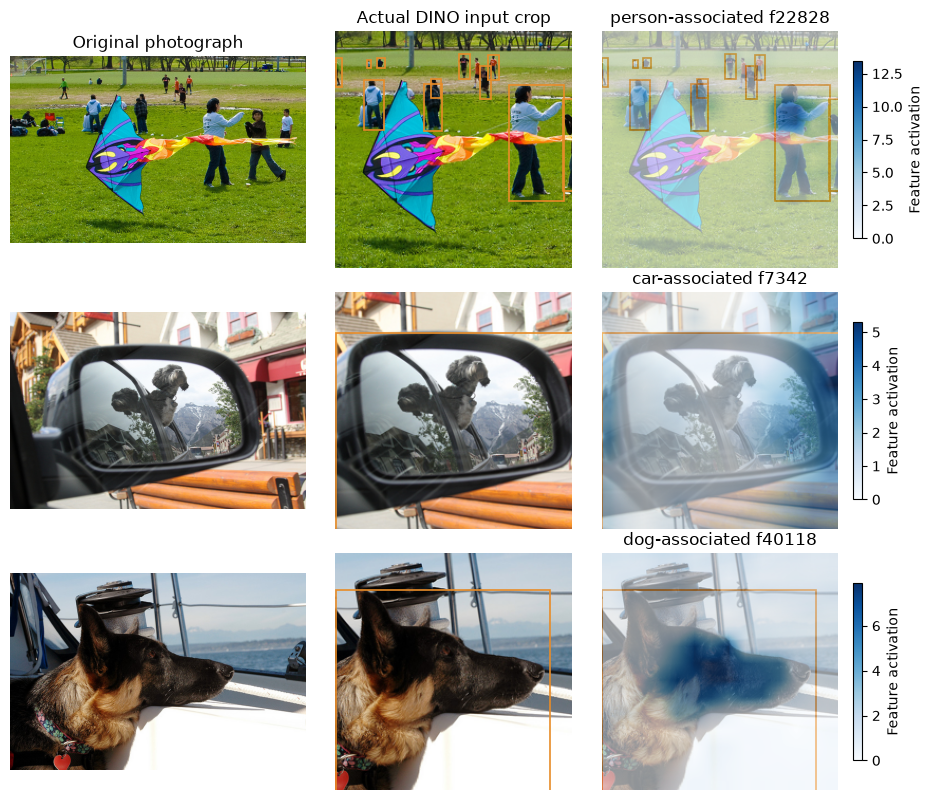

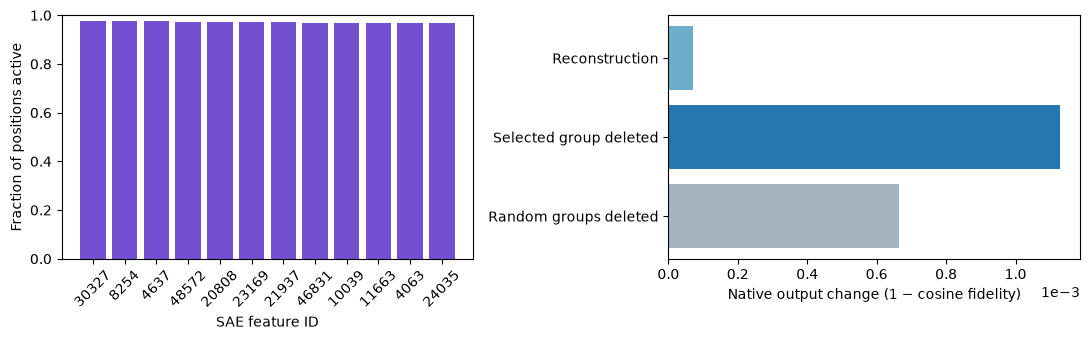

In [9]:
from matplotlib.patches import Rectangle

figure, axes = plt.subplots(3, 3, figsize=(9.4, 8.1))
for index, (record, original, (inputs, crop, boxes), result) in enumerate(
        zip(showcase_records, showcase_images, showcase_prepared, showcase_results)):
    category = record["category_id"]
    feature_id = selected[category]["feature_id"]
    axes[index, 0].imshow(original)
    axes[index, 0].axis("off")
    axes[index, 1].imshow(crop)
    axes[index, 1].axis("off")
    target_boxes = [box["bbox_xywh"] for box in boxes if box["category_id"] == category]
    plot_sae_feature_overlay(crop, result, feature_id=feature_id, grid_shape=GRID,
        image_alpha=.40, cmap="Blues", vmin=0, ax=axes[index, 2], colorbar=True,
        title=f"{categories[category]}-associated f{feature_id}")
    for column in (1, 2):
        for x, y, width, height in target_boxes:
            axes[index, column].add_patch(Rectangle((x, y), width, height,
                fill=False, edgecolor="#e88c28", linewidth=1.2))
    axes[index, 0].set_ylabel(categories[category])
axes[0, 0].set_title("Original photograph")
axes[0, 1].set_title("Actual DINO input crop")
figure.tight_layout()
figure.savefig(OUT / "pretrained_sae_features.png", dpi=160, bbox_inches="tight")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_sae_evaluation(model_report, top_k=12, ax=axes[0])
summary = model_report.summary
names = ["Reconstruction", "Selected group deleted", "Random groups deleted"]
scores = [summary["reconstruction.edited_score"], summary["target_scale_0.edited_score"],
          sum(summary[f"random_{repeat}_scale_0.edited_score"] for repeat in range(3)) / 3]
axes[1].barh(names, [1. - score for score in scores], color=["#6eaccb", "#2577ae", "#a5b3bf"])
axes[1].set(xlabel="Native output change (1 − cosine fidelity)", xlim=(0, None))
axes[1].ticklabel_format(axis="x", style="sci", scilimits=(-2, 2))
axes[1].invert_yaxis()
figure.tight_layout()
figure.savefig(OUT / "pretrained_sae_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()


## Reuse the loaded artifact and inspect provenance

The native artifact contains the converted dictionary, its exact binding and
source hashes. Reloading does not retrain the SAE. Evaluation reports store
explicit example IDs, metric definitions, feature IDs and random controls.
To analyze another model or layer, obtain a matching checkpoint and verify
its activation/preprocessing contract; changing a string is insufficient.

The tutorial demonstrates fresh extraction, reconstruction, observational
localization and representation interventions. It does not establish semantic
feature purity, answer correctness, cross-method superiority, or a causal
object-to-answer pathway. For the broader report comparisons, use the
separately described experimental protocols and full held-out datasets.


In [10]:
reloaded = probe.sae.load(OUT / "native_sae", binding=binding, tokens="visual", device=DEVICE)
with torch.no_grad():
    round_trip = reloaded.run(showcase_prepared[0][0])
torch.testing.assert_close(round_trip.tensors["features"], showcase_results[0].tensors["features"], rtol=0, atol=0)
result_summary = {
    "backbone": {"repo_id": MODEL_ID, "revision": MODEL_REVISION, "files_sha256": MODEL_FILES},
    "dictionary": {"repo_id": SAE_ID, "revision": SAE_REVISION, "files_sha256": SAE_FILES},
    "input_manifest_sha256": checksum(manifest_path), "source_formula_parity": parity,
    "calibration_images": 32, "held_out_images": 3, "weights_fitted_here": False,
    "selected_features": selected, "intervention_controls": intervention_rows,
    "reconstruction_and_intervention": model_report.summary,
    "localization": localization_report.summary,
    "figures": ["pretrained_sae_features.png", "pretrained_sae_evaluation.png"],
}
(OUT / "tutorial_summary.json").write_text(json.dumps(result_summary, indent=2, allow_nan=False) + "\n")
status("complete", calibration_images=32, held_out_images=3,
       selected_feature_ids=list(feature_ids), native_sae_training_steps=0,
       source_formula_parity=parity, no_op_max_abs_change=max(row["no_op_max_abs_change"] for row in intervention_rows))


{"status": "complete", "updated_unix": 1792980934.6097806, "calibration_images": 32, "held_out_images": 3, "selected_feature_ids": [7342, 22828, 40118], "native_sae_training_steps": 0, "source_formula_parity": {"positions": 16, "feature_max_abs_error": 9.5367431640625e-07, "reconstruction_max_abs_error": 9.5367431640625e-07}, "no_op_max_abs_change": 0.0}
